In [ ]:
!pip install tidy3d

In [ ]:
import numpy as np, json, matplotlib.pyplot as plt
import tidy3d as td
import tidy3d.web as web
print('tidy3d', td.__version__)

# ---- API key: Colab secret 'TIDY3D_API_KEY', else prompt ----
try:
    from google.colab import userdata
    _key = userdata.get("Enter code here")
except Exception:
    _key = None
if not _key:
    import getpass
    _key = getpass.getpass('Tidy3D API key: ')
web.configure(_key)

tidy3d 2.12.1
Tidy3D API key: ··········
Configuration saved successfully.


In [ ]:
# ================= user settings =================
MATERIAL = 'gold'       # 'gold' or 'bk7'
MODE     = 'single'     # 'single' (633 nm) or 'broadband' (450-800 nm, pole-fitted Etchegoin gold)
DL_NM    = 2.0          # uniform grid step (nm); try 1.0 to check FDTD convergence
DRY_RUN  = False        # True: build/plot only, do not submit
# =================================================
NM = 1e-3               # nm -> um (Tidy3D length unit)


In [ ]:
A_NM, D_ROSE, M_ROSE = 150.0, 0.25, 5
RMAX_NM = A_NM*(1 + D_ROSE)
LAM0_NM = 633.0
SPEC_NM = np.arange(450.0, 800.0 + 5, 10.0)
R_PROBE_NM = 300.0

def eps_gold(lam_nm):
    # Etchegoin, Le Ru, Meyer, J. Chem. Phys. 125, 164705 (2006); exp(-i w t), Im > 0
    l = np.asarray(lam_nm, float)
    e = 1.53 - 1.0/(145.0**2*(1/l**2 + 1j/(17000.0*l)))
    for A, ph, li, gi in [(0.94, -np.pi/4, 468.0, 2300.0), (1.36, -np.pi/4, 331.0, 940.0)]:
        e = e + A/li*(np.exp(1j*ph)/(1/li - 1/l - 1j/gi) + np.exp(-1j*ph)/(1/li + 1/l + 1j/gi))
    return e

BK7_B = [1.03961212, 0.231792344, 1.01046945]
BK7_C = [0.00600069867, 0.0200179144, 103.560653]   # um^2
print('eps_gold(633) =', np.round(eps_gold(633.0), 4))

eps_gold(633) = (-11.253+0.813j)


In [ ]:
REF = json.loads('{"gold":{"spec_lam":[450.0,460.0,470.0,480.0,490.0,500.0,510.0,520.0,530.0,540.0,550.0,560.0,570.0,580.0,590.0,600.0,610.0,620.0,630.0,640.0,650.0,660.0,670.0,680.0,690.0,700.0,710.0,720.0,730.0,740.0,750.0,760.0,770.0,780.0,790.0,800.0],"spec_Cext":[812.766666,814.224324,816.192811,819.636742,825.823448,835.829185,850.463813,870.854786,897.685763,929.825372,965.614885,1004.41267,1046.034758,1089.76338,1134.045152,1176.633565,1214.849201,1245.875349,1267.101716,1276.505115,1272.998434,1256.644622,1228.65276,1191.145419,1146.770705,1098.279491,1048.177422,998.510118,950.783929,905.988769,864.6791,827.075724,793.164106,762.777119,735.658618,711.508994],"spec_Csca":[445.489141,441.618694,438.79495,438.96492,444.956838,460.30075,489.145371,535.542877,599.674037,674.990801,752.786038,827.87483,898.791908,965.437455,1027.494283,1083.939574,1133.104224,1172.949029,1201.44292,1216.984373,1218.784725,1207.109934,1183.300254,1149.558574,1108.580694,1063.147155,1015.785517,968.561645,923.003206,880.123071,840.499721,804.378102,771.767039,742.521318,716.404845,693.136023],"spec_Cabs":[367.277526,372.60563,377.397861,380.671822,380.86661,375.528435,361.318441,335.311909,298.011726,254.83457,212.828848,176.53784,147.242849,124.325925,106.550869,92.693991,81.744977,72.92632,65.658796,59.520742,54.213709,49.534689,45.352506,41.586845,38.190011,35.132335,32.391905,29.948473,27.780723,25.865698,24.179379,22.697622,21.397067,20.255801,19.253773,18.372971],"probe_absHz":[0.80710981,0.806518294,0.804745318,0.801795599,0.797676989,0.792400466,0.785980121,0.778433147,0.769779834,0.760043572,0.749250866,0.737431376,0.724617978,0.710846858,0.696157659,0.680593664,0.664202058,0.647034264,0.629146378,0.610599721,0.591461544,0.571805904,0.551714764,0.531279356,0.510601853,0.489797422,0.468996682,0.448348612,0.428023886,0.408218496,0.38915738,0.371097447,0.354328985,0.339173874,0.325978547,0.315099502,0.306880017,0.301619043,0.299536905,0.300745905,0.305234683,0.312871607,0.323425842,0.336599029,0.35205858,0.369465764,0.388495449,0.408847575,0.430252108,0.452469624,0.475289373,0.498526126,0.522016656,0.545616308,0.569195879,0.592638906,0.615839365,0.638699739,0.661129437,0.683043496,0.704361526,0.725006875,0.744905964,0.763987783,0.782183516,0.799426288,0.815651008,0.830794315,0.844794598,0.857592092,0.869129042,0.879349919,0.888201686,0.895634101,0.901600049,0.906055896,0.908961848,0.910282319,0.909986283,0.908047617,0.904445415,0.899164279,0.892194567,0.883532611,0.873180885,0.861148134,0.847449455,0.832106333,0.815146632,0.796604546,0.776520501,0.754941024,0.731918575,0.707511339,0.681782994,0.654802449,0.626643553,0.597384791,0.567108956,0.535902812,0.503856747,0.471064425,0.437622443,0.403630008,0.36918865,0.334402012,0.299375771,0.264217819,0.229038989,0.193954968,0.159091171,0.124596076,0.090684403,0.057825212,0.028176462,0.021434333,0.046941021,0.076611197,0.106220402,0.135111638,0.163051405,0.189907942,0.215586415,0.240010221,0.263114358,0.284842786,0.305147314,0.323987172,0.341328896,0.357146377,0.371420999,0.38414182,0.395305788,0.404917963,0.412991751,0.41954914,0.424620922,0.428246922,0.430476199,0.431367243,0.430988137,0.429416696,0.426740561,0.423057233,0.418474032,0.413107946,0.40708534,0.400541454,0.393619647,0.386470279,0.379249164,0.37211546,0.365228938,0.358746547,0.352818299,0.34758256,0.343160992,0.339653497,0.337133656,0.335645168,0.335199789,0.335777056,0.337325905,0.33976798,0.34300223,0.346910274,0.351361974,0.356220768,0.361348414,0.366608976,0.371871992,0.377014871,0.381924607,0.386498952,0.390647149,0.394290362,0.397361885,0.399807213,0.40158403,0.40266217,0.403023556,0.40266217,0.40158403,0.399807213,0.397361885,0.394290362,0.390647149,0.386498952,0.381924607,0.377014871,0.371871992,0.366608976,0.361348414,0.356220768,0.351361974,0.346910274,0.34300223,0.33976798,0.337325905,0.335777056,0.335199789,0.335645168,0.337133656,0.339653497,0.343160992,0.34758256,0.352818299,0.358746547,0.365228938,0.37211546,0.379249164,0.386470279,0.393619647,0.400541454,0.40708534,0.413107946,0.418474032,0.423057233,0.426740561,0.429416696,0.430988137,0.431367243,0.430476199,0.428246922,0.424620922,0.41954914,0.412991751,0.404917963,0.395305788,0.38414182,0.371420999,0.357146377,0.341328896,0.323987172,0.305147314,0.284842786,0.263114358,0.240010221,0.215586415,0.189907942,0.163051405,0.135111638,0.106220402,0.076611197,0.046941021,0.021434333,0.028176462,0.057825212,0.090684403,0.124596076,0.159091171,0.193954968,0.229038989,0.264217819,0.299375771,0.334402012,0.36918865,0.403630008,0.437622443,0.471064425,0.503856747,0.535902812,0.567108956,0.597384791,0.626643553,0.654802449,0.681782994,0.707511339,0.731918575,0.754941024,0.776520501,0.796604546,0.815146632,0.832106333,0.847449455,0.861148134,0.873180885,0.883532611,0.892194567,0.899164279,0.904445415,0.908047617,0.909986283,0.910282319,0.908961848,0.906055896,0.901600049,0.895634101,0.888201686,0.879349919,0.869129042,0.857592092,0.844794598,0.830794315,0.815651008,0.799426288,0.782183516,0.763987783,0.744905964,0.725006875,0.704361526,0.683043496,0.661129437,0.638699739,0.615839365,0.592638906,0.569195879,0.545616308,0.522016656,0.498526126,0.475289373,0.452469624,0.430252108,0.408847575,0.388495449,0.369465764,0.35205858,0.336599029,0.323425842,0.312871607,0.305234683,0.300745905,0.299536905,0.301619043,0.306880017,0.315099502,0.325978547,0.339173874,0.354328985,0.371097447,0.38915738,0.408218496,0.428023886,0.448348612,0.468996682,0.489797422,0.510601853,0.531279356,0.551714764,0.571805904,0.591461544,0.610599721,0.629146378,0.647034264,0.664202058,0.680593664,0.696157659,0.710846858,0.724617978,0.737431376,0.749250866,0.760043572,0.769779834,0.778433147,0.785980121,0.792400466,0.797676989,0.801795599,0.804745318,0.806518294],"probe_absE":[0.549089848,0.549320768,0.550010867,0.551152261,0.552732096,0.554732976,0.557133505,0.559908942,0.563031912,0.566473141,0.570202188,0.574188137,0.578400229,0.582808411,0.587383797,0.592099034,0.596928565,0.601848814,0.606838273,0.611877521,0.616949172,0.622037776,0.627129664,0.632212767,0.637276395,0.642311009,0.647307969,0.652259275,0.657157308,0.661994562,0.666763389,0.67145574,0.676062918,0.680575338,0.684982303,0.68927179,0.69343025,0.697442433,0.701291222,0.704957499,0.708420034,0.711655397,0.714637907,0.717339617,0.719730337,0.721777699,0.723447277,0.724702762,0.725506201,0.725818302,0.725598826,0.724807065,0.723402419,0.721345086,0.718596879,0.715122175,0.71088903,0.705870454,0.700045877,0.693402824,0.685938807,0.677663466,0.66860095,0.658792571,0.648299702,0.637206915,0.625625286,0.613695774,0.601592482,0.589525512,0.577742979,0.566531563,0.556214804,0.547148194,0.53971013,0.534288064,0.531259855,0.530971403,0.53371292,0.539697277,0.549044115,0.561772581,0.577803706,0.59697133,0.619038827,0.643718309,0.670689334,0.699615148,0.730155513,0.761976042,0.794754467,0.82818447,0.861977745,0.895864829,0.929595177,0.962936779,0.995675541,1.027614585,1.05857355,1.088387932,1.116908512,1.144000864,1.169544959,1.193434845,1.21557842,1.235897275,1.25432661,1.270815218,1.285325534,1.297833741,1.308329948,1.316818418,1.323317859,1.327861778,1.330498888,1.331293569,1.330326375,1.327694578,1.323512719,1.317913158,1.311046572,1.30308235,1.294208828,1.284633264,1.274581467,1.264296939,1.254039397,1.244082537,1.234710888,1.226215641,1.21888941,1.213019909,1.208882712,1.206733328,1.20679901,1.20927081,1.21429647,1.221974751,1.232351696,1.245419185,1.261115887,1.279330522,1.299907067,1.322651476,1.347339308,1.373723758,1.401543569,1.430530451,1.460415735,1.490936098,1.521838288,1.552882864,1.583846991,1.614526391,1.644736546,1.674313256,1.703112663,1.731010838,1.757903025,1.783702605,1.808339881,1.831760701,1.853925016,1.874805371,1.8943854,1.912658325,1.929625499,1.945295003,1.959680305,1.972799002,1.984671644,1.995320647,2.004769292,2.013040832,2.020157676,2.026140682,2.031008541,2.034777251,2.0374597,2.039065328,2.039599892,2.039065328,2.0374597,2.034777251,2.031008541,2.026140682,2.020157676,2.013040832,2.004769292,1.995320647,1.984671644,1.972799002,1.959680305,1.945295003,1.929625499,1.912658325,1.8943854,1.874805371,1.853925016,1.831760701,1.808339881,1.783702605,1.757903025,1.731010838,1.703112663,1.674313256,1.644736546,1.614526391,1.583846991,1.552882864,1.521838288,1.490936098,1.460415735,1.430530451,1.401543569,1.373723758,1.347339308,1.322651476,1.299907067,1.279330522,1.261115887,1.245419185,1.232351696,1.221974751,1.21429647,1.20927081,1.20679901,1.206733328,1.208882712,1.213019909,1.21888941,1.226215641,1.234710888,1.244082537,1.254039397,1.264296939,1.274581467,1.284633264,1.294208828,1.30308235,1.311046572,1.317913158,1.323512719,1.327694578,1.330326375,1.331293569,1.330498888,1.327861778,1.323317859,1.316818418,1.308329948,1.297833741,1.285325534,1.270815218,1.25432661,1.235897275,1.21557842,1.193434845,1.169544959,1.144000864,1.116908512,1.088387932,1.05857355,1.027614585,0.995675541,0.962936779,0.929595177,0.895864829,0.861977745,0.82818447,0.794754467,0.761976042,0.730155513,0.699615148,0.670689334,0.643718309,0.619038827,0.59697133,0.577803706,0.561772581,0.549044115,0.539697277,0.53371292,0.530971403,0.531259855,0.534288064,0.53971013,0.547148194,0.556214804,0.566531563,0.577742979,0.589525512,0.601592482,0.613695774,0.625625286,0.637206915,0.648299702,0.658792571,0.66860095,0.677663466,0.685938807,0.693402824,0.700045877,0.705870454,0.71088903,0.715122175,0.718596879,0.721345086,0.723402419,0.724807065,0.725598826,0.725818302,0.725506201,0.724702762,0.723447277,0.721777699,0.719730337,0.717339617,0.714637907,0.711655397,0.708420034,0.704957499,0.701291222,0.697442433,0.69343025,0.68927179,0.684982303,0.680575338,0.676062918,0.67145574,0.666763389,0.661994562,0.657157308,0.652259275,0.647307969,0.642311009,0.637276395,0.632212767,0.627129664,0.622037776,0.616949172,0.611877521,0.606838273,0.601848814,0.596928565,0.592099034,0.587383797,0.582808411,0.578400229,0.574188137,0.570202188,0.566473141,0.563031912,0.559908942,0.557133505,0.554732976,0.552732096,0.551152261,0.550010867,0.549320768],"sigma":[4204.581572,4201.149503,4190.865632,4173.76692,4149.914791,4119.394868,4082.316612,4038.812845,3989.039188,3933.173394,3871.414585,3803.982407,3731.116085,3653.073413,3570.129646,3482.576337,3390.720097,3294.881296,3195.392707,3092.598103,2986.850811,2878.512232,2767.950325,2655.538079,2541.651965,2426.670382,2310.972105,2194.934739,2078.933191,1963.338161,1848.514666,1734.8206,1622.605337,1512.208387,1403.958106,1298.170467,1195.147908,1095.178245,998.533665,905.469807,816.224927,731.01915,650.053821,573.510949,501.552747,434.321272,371.938162,314.504477,262.100631,214.786428,172.601185,135.56396,103.673857,76.910427,55.234146,38.586978,26.893002,20.059121,17.975819,20.517988,27.5458,38.905628,54.431,73.943595,97.254259,124.164039,154.465238,187.942471,224.373728,263.531424,305.18345,349.094198,395.025575,442.737984,491.991283,542.545705,594.162746,646.60601,699.642019,753.040969,806.577452,860.031121,913.187316,965.837642,1017.780492,1068.821535,1118.774152,1167.459825,1214.708492,1260.358855,1304.258647,1346.26487,1386.243994,1424.07212,1459.635123,1492.828759,1523.558749,1551.740846,1577.300872,1600.174743,1620.308473,1637.658162,1652.189975,1663.880094,1672.71467,1678.689755,1681.811218,1682.094651,1679.56526,1674.257733,1666.216105,1655.493583,1642.152371,1626.263461,1607.906396,1587.169019,1564.14718,1538.944422,1511.671625,1482.446625,1451.393793,1418.64357,1384.331982,1348.600095,1311.593453,1273.46146,1234.356741,1194.434459,1153.851602,1112.766243,1071.336771,1029.721104,988.075879,946.555633,905.311979,864.492781,824.24133,784.695541,745.987162,708.241016,671.574276,636.095775,601.905378,569.093397,537.740076,507.915144,479.677437,453.074609,428.14292,404.907119,383.380408,363.564515,345.449845,329.015741,314.230829,301.053463,289.432255,279.306694,270.607847,263.259136,257.17718,252.272711,248.451529,245.615513,243.663666,242.493181,242.000528,242.082542,242.637511,243.566238,244.773085,246.166973,247.662338,249.180021,250.648105,252.00266,253.188417,254.159345,254.879133,255.321567,255.470811,255.321567,254.879133,254.159345,253.188417,252.00266,250.648105,249.180021,247.662338,246.166973,244.773085,243.566238,242.637511,242.082542,242.000528,242.493181,243.663666,245.615513,248.451529,252.272711,257.17718,263.259136,270.607847,279.306694,289.432255,301.053463,314.230829,329.015741,345.449845,363.564515,383.380408,404.907119,428.14292,453.074609,479.677437,507.915144,537.740076,569.093397,601.905378,636.095775,671.574276,708.241016,745.987162,784.695541,824.24133,864.492781,905.311979,946.555633,988.075879,1029.721104,1071.336771,1112.766243,1153.851602,1194.434459,1234.356741,1273.46146,1311.593453,1348.600095,1384.331982,1418.64357,1451.393793,1482.446625,1511.671625,1538.944422,1564.14718,1587.169019,1607.906396,1626.263461,1642.152371,1655.493583,1666.216105,1674.257733,1679.56526,1682.094651,1681.811218,1678.689755,1672.71467,1663.880094,1652.189975,1637.658162,1620.308473,1600.174743,1577.300872,1551.740846,1523.558749,1492.828759,1459.635123,1424.07212,1386.243994,1346.26487,1304.258647,1260.358855,1214.708492,1167.459825,1118.774152,1068.821535,1017.780492,965.837642,913.187316,860.031121,806.577452,753.040969,699.642019,646.60601,594.162746,542.545705,491.991283,442.737984,395.025575,349.094198,305.18345,263.531424,224.373728,187.942471,154.465238,124.164039,97.254259,73.943595,54.431,38.905628,27.5458,20.517988,17.975819,20.059121,26.893002,38.586978,55.234146,76.910427,103.673857,135.56396,172.601185,214.786428,262.100631,314.504477,371.938162,434.321272,501.552747,573.510949,650.053821,731.01915,816.224927,905.469807,998.533665,1095.178245,1195.147908,1298.170467,1403.958106,1512.208387,1622.605337,1734.8206,1848.514666,1963.338161,2078.933191,2194.934739,2310.972105,2426.670382,2541.651965,2655.538079,2767.950325,2878.512232,2986.850811,3092.598103,3195.392707,3294.881296,3390.720097,3482.576337,3570.129646,3653.073413,3731.116085,3803.982407,3871.414585,3933.173394,3989.039188,4038.812845,4082.316612,4119.394868,4149.914791,4173.76692,4190.865632,4201.149503],"Cext":1271.2343567383,"Csca":1207.5198780535,"Cabs":63.7144786847},"bk7":{"spec_lam":[450.0,460.0,470.0,480.0,490.0,500.0,510.0,520.0,530.0,540.0,550.0,560.0,570.0,580.0,590.0,600.0,610.0,620.0,630.0,640.0,650.0,660.0,670.0,680.0,690.0,700.0,710.0,720.0,730.0,740.0,750.0,760.0,770.0,780.0,790.0,800.0],"spec_Cext":[671.936299,642.800368,615.50583,589.891411,565.752954,542.872106,521.037157,500.057412,479.77242,460.057041,440.823081,422.018088,403.621822,385.64101,368.102987,351.048886,334.527004,318.586846,303.274239,288.627698,274.676094,261.43752,248.919158,237.117914,226.021583,215.610305,205.858147,196.734649,188.20627,180.237644,172.79265,165.83527,159.330258,153.243638,147.543056,142.198006],"spec_Csca":[671.936299,642.800368,615.50583,589.891411,565.752954,542.872106,521.037157,500.057412,479.77242,460.057041,440.823081,422.018088,403.621822,385.64101,368.102987,351.048886,334.527004,318.586846,303.274239,288.627698,274.676094,261.43752,248.919158,237.117914,226.021583,215.610305,205.858147,196.734649,188.20627,180.237644,172.79265,165.83527,159.330258,153.243638,147.543056,142.198006],"spec_Cabs":[-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"probe_absHz":[1.403725597,1.403340762,1.402186966,1.400266331,1.397582381,1.394140015,1.389945476,1.385006319,1.379331362,1.372930645,1.365815379,1.357997903,1.349491633,1.340311023,1.330471526,1.31998956,1.308882486,1.297168585,1.28486705,1.271997981,1.258582392,1.244642222,1.230200362,1.21528068,1.199908058,1.184108445,1.167908904,1.151337674,1.134424245,1.117199427,1.099695438,1.081945997,1.063986419,1.045853722,1.02758674,1.009226237,0.990815031,0.972398114,0.954022776,0.935738723,0.917598184,0.899656003,0.881969711,0.864599557,0.847608498,0.831062127,0.815028523,0.799578008,0.784782782,0.770716433,0.757453287,0.745067594,0.733632538,0.723219085,0.713894656,0.705721692,0.698756125,0.693045835,0.688629162,0.685533553,0.683774438,0.683354394,0.684262674,0.686475111,0.689954434,0.694650947,0.700503534,0.707440927,0.715383158,0.724243111,0.73392811,0.74434147,0.755383978,0.76695525,0.778954958,0.791283916,0.803845016,0.816544038,0.829290325,0.841997349,0.854583178,0.866970847,0.879088666,0.890870449,0.902255695,0.913189709,0.923623689,0.93351477,0.942826027,0.95152646,0.959590933,0.967000102,0.973740312,0.979803465,0.985186875,0.989893097,0.993929737,0.997309238,1.000048651,1.002169385,1.003696933,1.004660587,1.005093125,1.005030486,1.004511419,1.003577123,1.00227086,1.000637562,0.99872341,0.996575412,0.994240968,0.991767421,0.989201613,0.986589437,0.983975394,0.981402168,0.978910207,0.976537334,0.974318392,0.972284916,0.970464848,0.968882312,0.967557426,0.966506177,0.965740362,0.965267574,0.965091267,0.965210864,0.965621927,0.966316388,0.967282806,0.968506686,0.969970817,0.971655644,0.973539651,0.975599764,0.977811751,0.980150624,0.982591022,0.985107591,0.987675337,0.990269946,0.992868092,0.995447694,0.997988148,1.000470525,1.002877718,1.005194568,1.007407937,1.009506755,1.011482027,1.013326811,1.015036165,1.016607066,1.018038313,1.019330402,1.020485395,1.021506769,1.022399265,1.023168722,1.023821922,1.024366426,1.024810414,1.025162536,1.025431761,1.02562724,1.025758176,1.025833701,1.025862764,1.025854032,1.025815789,1.025755861,1.025681538,1.025599506,1.025515795,1.025435722,1.025363859,1.025303989,1.025259084,1.025231282,1.025221871,1.025231282,1.025259084,1.025303989,1.025363859,1.025435722,1.025515795,1.025599506,1.025681538,1.025755861,1.025815789,1.025854032,1.025862764,1.025833701,1.025758176,1.02562724,1.025431761,1.025162536,1.024810414,1.024366426,1.023821922,1.023168722,1.022399265,1.021506769,1.020485395,1.019330402,1.018038313,1.016607066,1.015036165,1.013326811,1.011482027,1.009506755,1.007407937,1.005194568,1.002877718,1.000470525,0.997988148,0.995447694,0.992868092,0.990269946,0.987675337,0.985107591,0.982591022,0.980150624,0.977811751,0.975599764,0.973539651,0.971655644,0.969970817,0.968506686,0.967282806,0.966316388,0.965621927,0.965210864,0.965091267,0.965267574,0.965740362,0.966506177,0.967557426,0.968882312,0.970464848,0.972284916,0.974318392,0.976537334,0.978910207,0.981402168,0.983975394,0.986589437,0.989201613,0.991767421,0.994240968,0.996575412,0.99872341,1.000637562,1.00227086,1.003577123,1.004511419,1.005030486,1.005093125,1.004660587,1.003696933,1.002169385,1.000048651,0.997309238,0.993929737,0.989893097,0.985186875,0.979803465,0.973740312,0.967000102,0.959590933,0.95152646,0.942826027,0.93351477,0.923623689,0.913189709,0.902255695,0.890870449,0.879088666,0.866970847,0.854583178,0.841997349,0.829290325,0.816544038,0.803845016,0.791283916,0.778954958,0.76695525,0.755383978,0.74434147,0.73392811,0.724243111,0.715383158,0.707440927,0.700503534,0.694650947,0.689954434,0.686475111,0.684262674,0.683354394,0.683774438,0.685533553,0.688629162,0.693045835,0.698756125,0.705721692,0.713894656,0.723219085,0.733632538,0.745067594,0.757453287,0.770716433,0.784782782,0.799578008,0.815028523,0.831062127,0.847608498,0.864599557,0.881969711,0.899656003,0.917598184,0.935738723,0.954022776,0.972398114,0.990815031,1.009226237,1.02758674,1.045853722,1.063986419,1.081945997,1.099695438,1.117199427,1.134424245,1.151337674,1.167908904,1.184108445,1.199908058,1.21528068,1.230200362,1.244642222,1.258582392,1.271997981,1.28486705,1.297168585,1.308882486,1.31998956,1.330471526,1.340311023,1.349491633,1.357997903,1.365815379,1.372930645,1.379331362,1.385006319,1.389945476,1.394140015,1.397582381,1.400266331,1.402186966,1.403340762],"probe_absE":[1.254666518,1.254489103,1.253956967,1.253070441,1.251830109,1.25023684,1.248291844,1.245996733,1.24335359,1.24036504,1.23703433,1.233365391,1.229362917,1.225032418,1.220380284,1.215413826,1.210141322,1.204572048,1.198716307,1.19258545,1.186191897,1.179549146,1.172671788,1.165575518,1.15827714,1.150794575,1.143146866,1.135354177,1.127437798,1.11942013,1.111324679,1.103176026,1.094999798,1.086822615,1.078672024,1.070576411,1.062564885,1.054667137,1.046913267,1.039333577,1.03195832,1.024817421,1.017940147,1.011354747,1.005088046,0.999165015,0.993608302,0.988437749,0.983669906,0.979317532,0.975389126,0.971888483,0.96881431,0.966159895,0.963912872,0.962055091,0.960562593,0.959405728,0.9585494,0.957953471,0.957573299,0.957360419,0.957263368,0.957228615,0.957201606,0.957127884,0.956954258,0.956630006,0.95610807,0.955346206,0.954308073,0.952964222,0.951292944,0.949280982,0.946924045,0.944227151,0.941204745,0.937880616,0.9342876,0.930467066,0.926468207,0.922347136,0.918165809,0.913990795,0.909891914,0.905940775,0.902209243,0.898767867,0.895684314,0.893021846,0.890837885,0.889182706,0.888098305,0.887617473,0.887763107,0.888547783,0.889973602,0.8920323,0.894705613,0.897965888,0.901776877,0.906094709,0.910868973,0.916043885,0.921559483,0.927352829,0.933359171,0.939513049,0.945749318,0.952004083,0.958215527,0.96432464,0.970275843,0.97601751,0.981502399,0.986687996,0.991536775,0.996016392,1.000099807,1.003765362,1.006996786,1.009783178,1.012118925,1.014003598,1.015441803,1.016442993,1.017021253,1.017195044,1.016986906,1.016423132,1.015533393,1.014350329,1.012909095,1.011246867,1.00940231,1.007415016,1.005324904,1.003171615,1.000993887,0.998828945,0.996711907,0.994675233,0.992748227,0.990956616,0.989322208,0.98786266,0.986591345,0.985517332,0.984645477,0.983976613,0.983507836,0.983232861,0.983142445,0.983224843,0.983466291,0.983851486,0.984364059,0.984987012,0.985703123,0.986495302,0.987346888,0.988241904,0.989165252,0.990102853,0.991041745,0.99197014,0.992877437,0.993754212,0.994592176,0.995384117,0.996123833,0.996806042,0.997426303,0.997980925,0.998466882,0.998881733,0.999223545,0.999490832,0.999682496,0.999797786,0.999836264,0.999797786,0.999682496,0.999490832,0.999223545,0.998881733,0.998466882,0.997980925,0.997426303,0.996806042,0.996123833,0.995384117,0.994592176,0.993754212,0.992877437,0.99197014,0.991041745,0.990102853,0.989165252,0.988241904,0.987346888,0.986495302,0.985703123,0.984987012,0.984364059,0.983851486,0.983466291,0.983224843,0.983142445,0.983232861,0.983507836,0.983976613,0.984645477,0.985517332,0.986591345,0.98786266,0.989322208,0.990956616,0.992748227,0.994675233,0.996711907,0.998828945,1.000993887,1.003171615,1.005324904,1.007415016,1.00940231,1.011246867,1.012909095,1.014350329,1.015533393,1.016423132,1.016986906,1.017195044,1.017021253,1.016442993,1.015441803,1.014003598,1.012118925,1.009783178,1.006996786,1.003765362,1.000099807,0.996016392,0.991536775,0.986687996,0.981502399,0.97601751,0.970275843,0.96432464,0.958215527,0.952004083,0.945749318,0.939513049,0.933359171,0.927352829,0.921559483,0.916043885,0.910868973,0.906094709,0.901776877,0.897965888,0.894705613,0.8920323,0.889973602,0.888547783,0.887763107,0.887617473,0.888098305,0.889182706,0.890837885,0.893021846,0.895684314,0.898767867,0.902209243,0.905940775,0.909891914,0.913990795,0.918165809,0.922347136,0.926468207,0.930467066,0.9342876,0.937880616,0.941204745,0.944227151,0.946924045,0.949280982,0.951292944,0.952964222,0.954308073,0.955346206,0.95610807,0.956630006,0.956954258,0.957127884,0.957201606,0.957228615,0.957263368,0.957360419,0.957573299,0.957953471,0.9585494,0.959405728,0.960562593,0.962055091,0.963912872,0.966159895,0.96881431,0.971888483,0.975389126,0.979317532,0.983669906,0.988437749,0.993608302,0.999165015,1.005088046,1.011354747,1.017940147,1.024817421,1.03195832,1.039333577,1.046913267,1.054667137,1.062564885,1.070576411,1.078672024,1.086822615,1.094999798,1.103176026,1.111324679,1.11942013,1.127437798,1.135354177,1.143146866,1.150794575,1.15827714,1.165575518,1.172671788,1.179549146,1.186191897,1.19258545,1.198716307,1.204572048,1.210141322,1.215413826,1.220380284,1.225032418,1.229362917,1.233365391,1.23703433,1.24036504,1.24335359,1.245996733,1.248291844,1.25023684,1.251830109,1.253070441,1.253956967,1.254489103],"sigma":[1290.683355,1290.09891,1288.347093,1285.432449,1281.362536,1276.14789,1269.801985,1262.341177,1253.784641,1244.154288,1233.474685,1221.772949,1209.078644,1195.423664,1180.842103,1165.370125,1149.045822,1131.909064,1114.001348,1095.365639,1076.046206,1056.088457,1035.538767,1014.444313,992.852896,970.812773,948.372485,925.580686,902.485979,879.136747,855.580999,831.866207,808.039161,784.145822,760.231182,736.339136,712.512356,688.792177,665.218487,641.829631,618.662317,595.751541,573.130512,550.830591,528.881242,507.309984,486.142362,465.401925,445.110205,425.286721,405.948976,387.112471,368.790727,350.99531,333.73587,317.020182,300.854194,285.242084,270.186318,255.687717,241.745527,228.357491,215.519927,203.227808,191.474843,180.253559,169.555391,159.370761,149.689168,140.499273,131.788979,123.545522,115.755547,108.405191,101.480158,94.965799,88.847181,83.109159,77.736439,72.713648,68.025384,63.656283,59.591061,55.814571,52.311845,49.068132,46.068942,43.300076,40.747657,38.398158,36.238424,34.255695,32.437623,30.772284,29.248192,27.85431,26.580052,25.415292,24.350367,23.376074,22.483673,21.664882,20.911877,20.217282,19.574168,18.976047,18.41686,17.890973,17.393168,16.918634,16.462958,16.022117,15.592467,15.170735,14.754009,14.339726,13.925665,13.509937,13.090972,12.667512,12.238596,11.803553,11.361986,10.913766,10.459013,9.998086,9.531569,9.060255,8.585132,8.107366,7.628284,7.149356,6.672178,6.198449,5.729953,5.268541,4.816103,4.374553,3.945802,3.531739,3.134208,2.754985,2.395757,2.058103,1.743471,1.453162,1.18831,0.949866,0.738588,0.555021,0.399494,0.272109,0.172733,0.101,0.056309,0.037823,0.044481,0.074999,0.127887,0.201459,0.293848,0.403028,0.526832,0.662975,0.809078,0.962697,1.121345,1.282522,1.443743,1.602567,1.756625,1.903647,2.041488,2.168154,2.281825,2.380877,2.463903,2.529726,2.577416,2.606301,2.615975,2.606301,2.577416,2.529726,2.463903,2.380877,2.281825,2.168154,2.041488,1.903647,1.756625,1.602567,1.443743,1.282522,1.121345,0.962697,0.809078,0.662975,0.526832,0.403028,0.293848,0.201459,0.127887,0.074999,0.044481,0.037823,0.056309,0.101,0.172733,0.272109,0.399494,0.555021,0.738588,0.949866,1.18831,1.453162,1.743471,2.058103,2.395757,2.754985,3.134208,3.531739,3.945802,4.374553,4.816103,5.268541,5.729953,6.198449,6.672178,7.149356,7.628284,8.107366,8.585132,9.060255,9.531569,9.998086,10.459013,10.913766,11.361986,11.803553,12.238596,12.667512,13.090972,13.509937,13.925665,14.339726,14.754009,15.170735,15.592467,16.022117,16.462958,16.918634,17.393168,17.890973,18.41686,18.976047,19.574168,20.217282,20.911877,21.664882,22.483673,23.376074,24.350367,25.415292,26.580052,27.85431,29.248192,30.772284,32.437623,34.255695,36.238424,38.398158,40.747657,43.300076,46.068942,49.068132,52.311845,55.814571,59.591061,63.656283,68.025384,72.713648,77.736439,83.109159,88.847181,94.965799,101.480158,108.405191,115.755547,123.545522,131.788979,140.499273,149.689168,159.370761,169.555391,180.253559,191.474843,203.227808,215.519927,228.357491,241.745527,255.687717,270.186318,285.242084,300.854194,317.020182,333.73587,350.99531,368.790727,387.112471,405.948976,425.286721,445.110205,465.401925,486.142362,507.309984,528.881242,550.830591,573.130512,595.751541,618.662317,641.829631,665.218487,688.792177,712.512356,736.339136,760.231182,784.145822,808.039161,831.866207,855.580999,879.136747,902.485979,925.580686,948.372485,970.812773,992.852896,1014.444313,1035.538767,1056.088457,1076.046206,1095.365639,1114.001348,1131.909064,1149.045822,1165.370125,1180.842103,1195.423664,1209.078644,1221.772949,1233.474685,1244.154288,1253.784641,1262.341177,1269.801985,1276.14789,1281.362536,1285.432449,1288.347093,1290.09891],"Cext":298.8088249321,"Csca":298.8088249321,"Cabs":0.0}}')
for m in ('gold','bk7'):
    print(m, 'Cext=%.4f Csca=%.4f Cabs=%.4f nm' % (REF[m]['Cext'], REF[m]['Csca'], REF[m]['Cabs']))

gold Cext=1271.2344 Csca=1207.5199 Cabs=63.7145 nm
bk7 Cext=298.8088 Csca=298.8088 Cabs=0.0000 nm


eps(633 nm) in Tidy3D = -11.25301+0.81296j
domain 2.00 x 2.00 um, grid 2.0 nm, 1,098,304 cells


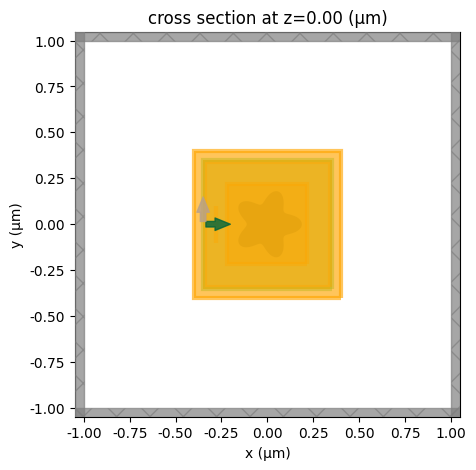

In [ ]:
t = np.linspace(0, 2*np.pi, 2048, endpoint=False)
rho = A_NM*(1 + D_ROSE*np.cos(M_ROSE*t))
verts = np.column_stack([rho*np.cos(t), rho*np.sin(t)])*NM

lam0 = LAM0_NM*NM
lams = np.array([lam0]) if MODE == 'single' else SPEC_NM*NM
freqs = td.C_0/lams
f0 = 0.5*(freqs.max() + freqs.min())
fwidth = f0/10 if MODE == 'single' else 0.6*(freqs.max() - freqs.min())

if MATERIAL == 'gold':
    if MODE == 'single':
        n = np.sqrt(eps_gold(LAM0_NM))
        medium = td.Lorentz.from_nk(n.real, n.imag, td.C_0/lam0)        # exact eps at 633 nm
    else:
        from tidy3d.plugins.dispersion import FastDispersionFitter
        lf = np.arange(440.0, 811.0, 5.0); nk = np.sqrt(eps_gold(lf))
        medium, rms = FastDispersionFitter(wvl_um=lf*NM, n_data=nk.real, k_data=nk.imag).fit(
            min_num_poles=1, max_num_poles=6, tolerance_rms=1e-5)
        print(f'pole fit of Etchegoin gold: weighted RMS = {rms:.2e}')
else:
    medium = td.Sellmeier(coeffs=list(zip(BK7_B, BK7_C)))
for lam, f in list(zip(lams, freqs))[:3]:
    print(f'eps({lam/NM:.0f} nm) in Tidy3D = {complex(medium.eps_model(f)):.5f}')

scatterer = td.Structure(geometry=td.PolySlab(vertices=verts, axis=2, slab_bounds=(-td.inf, td.inf)), medium=medium)

r_probe = R_PROBE_NM*NM
h_abs  = RMAX_NM*NM + 0.03          # box around the object (total field)  -> C_abs
h_tfsf = r_probe + 0.05             # TFSF region contains the probe circle
h_sca  = h_tfsf + 0.05              # box in the scattered-field region     -> C_sca, far field
L = 2*(h_sca + 0.6)

src = td.TFSF(center=(0, 0, 0), size=(2*h_tfsf, 2*h_tfsf, td.inf),
              source_time=td.GaussianPulse(freq0=f0, fwidth=fwidth),
              injection_axis=0, direction='+', pol_angle=0.0)          # +x, Ey -> TE_z
w_line = 0.2
phis = np.deg2rad(np.arange(0, 360, 1.0))
monitors = [
    td.FluxMonitor(center=(0, 0, 0), size=(2*h_sca, 2*h_sca, td.inf), freqs=list(freqs), name='sca'),
    td.FluxMonitor(center=(0, 0, 0), size=(2*h_abs, 2*h_abs, td.inf), freqs=list(freqs), name='abs'),
    td.FluxMonitor(center=(-0.8*h_tfsf, 0, 0), size=(0, w_line, td.inf), freqs=list(freqs), name='inc'),
    td.FieldMonitor(center=(0, 0, 0), size=(2*h_tfsf - 0.02, 2*h_tfsf - 0.02, 0),
                    freqs=[td.C_0/lam0], fields=['Ex', 'Ey', 'Hz'], name='field'),
    td.FieldProjectionAngleMonitor(center=(0, 0, 0), size=(2*h_sca, 2*h_sca, td.inf), freqs=[td.C_0/lam0],
                                   name='ff', phi=list(phis), theta=[np.pi/2], proj_distance=1e6, far_field_approx=True),
]

def make_sim(with_object):
    return td.Simulation(
        size=(L, L, 0), grid_spec=td.GridSpec.uniform(dl=DL_NM*NM),
        structures=[scatterer] if with_object else [], sources=[src], monitors=monitors,
        boundary_spec=td.BoundarySpec(x=td.Boundary.pml(num_layers=24), y=td.Boundary.pml(num_layers=24),
                                      z=td.Boundary.periodic()),
        run_time=4e-12 if MODE == 'single' else 1e-12, shutoff=1e-7)

sim, sim0 = make_sim(True), make_sim(False)
print(f'domain {L:.2f} x {L:.2f} um, grid {DL_NM} nm, {sim.num_cells:,} cells')
fig, ax = plt.subplots(figsize=(5, 5)); sim.plot(z=0, ax=ax); plt.show()

In [ ]:
import time
tag = f'{MATERIAL}_{MODE}_dl{DL_NM:g}'
if DRY_RUN:
    print('DRY_RUN = True: nothing submitted.')
else:
    acc = web.account()                                   # check credits are valid before submitting
    print('credit:', acc.credit, ' expires:', acc.credit_expiration)

    stamp  = time.strftime('%Y%m%d_%H%M%S')
    folder = f'sim2d_rose_{stamp}'                        # fresh folder every run
    names  = {'obj': f'rose_{tag}_{stamp}', 'norm': f'rose_{tag}_norm_{stamp}'}
    try:
        batch = web.Batch(simulations={names['obj']: sim, names['norm']: sim0}, folder_name=folder)
        print('estimated FlexCredits:', batch.estimate_cost())
        bdata = batch.run(path_dir=f'data_{tag}_{stamp}')
        data, data0 = bdata[names['obj']], bdata[names['norm']]
    except Exception as err:
        print('Batch failed (', type(err).__name__, '):', str(err)[:200], '\n-> running the two tasks one by one')
        data  = web.run(sim,  task_name=names['obj'],  folder_name=folder, path=f'{names["obj"]}.hdf5')
        data0 = web.run(sim0, task_name=names['norm'], folder_name=folder, path=f'{names["norm"]}.hdf5')

00:40:11 UTC Current FlexCredit balance: 50.00 and expiration date: 2027-10-18  
             23:59:59. Monthly FlexCredit balance: 10.00 and expiration date:   
             2026-10-31 23:59:59. Remaining daily free simulations: 0.

credit: 50.0  expires: 2027-10-18 23:59:59.999999+00:00


00:40:17 UTC Maximum FlexCredit cost: 0.601 for the whole batch.

Output()

estimated FlexCredits: 0.6007352968563708


00:40:19 UTC Started working on Batch containing 2 tasks.

00:40:21 UTC Maximum FlexCredit cost: 0.601 for the whole batch.

             Use 'Batch.real_cost()' to get the billed FlexCredit cost after    
             completion.

Output()

00:41:56 UTC Batch complete.

In [ ]:
R = REF[MATERIAL]
I0   = np.asarray(data0['inc'].flux)/w_line                 # incident intensity (flux per width)
Csca = np.asarray(data['sca'].flux)/I0/NM                    # nm
Cabs = -np.asarray(data['abs'].flux)/I0/NM
Cext = Csca + Cabs
i0 = int(np.argmin(abs(lams - lam0)))
print('633 nm         Tidy3D        sim2d     diff/Cext')
for nm_, a, b in (('Cext', Cext[i0], R['Cext']), ('Csca', Csca[i0], R['Csca']), ('Cabs', Cabs[i0], R['Cabs'])):
    print(f'{nm_:5s} {a:14.4f} {b:12.4f}   {abs(a-b)/R["Cext"]:.2e}')

# probe circle r = 300 nm (ratio to the empty run removes source normalization and phase)
import xarray as xr
fsel = td.C_0/lam0
xp, yp = r_probe*np.cos(phis), r_probe*np.sin(phis)
XP, YP = xr.DataArray(xp, dims='p'), xr.DataArray(yp, dims='p')
def on_circle(fd, comp):
    F = getattr(fd, comp).sel(f=fsel, method='nearest')     # FieldData components are attributes
    if 'z' in F.dims:
        F = F.isel(z=0)
    return np.asarray(F.interp(x=XP, y=YP).values).ravel()
Hz, Ex, Ey    = (on_circle(data['field'],  c) for c in ('Hz', 'Ex', 'Ey'))
Hz0, Ex0, Ey0 = (on_circle(data0['field'], c) for c in ('Hz', 'Ex', 'Ey'))
absHz = abs(Hz/Hz0)
absE  = np.sqrt(abs(Ex)**2 + abs(Ey)**2)/np.sqrt(abs(Ex0)**2 + abs(Ey0)**2)
print(f'probe: max|d(|Hz|/|Hzinc|)| = {np.max(abs(absHz - np.array(R["probe_absHz"]))):.2e},  '
      f'max|d(|E|/|Einc|)| = {np.max(abs(absE - np.array(R["probe_absE"]))):.2e}')

# far field: sigma(phi) = 2 pi r |Es|^2/|Einc|^2, checked against C_sca = mean(sigma)
ff = data['ff']
r_ff = getattr(ff, 'proj_distance', None) or ff.monitor.proj_distance
Es2 = np.squeeze(np.abs(ff.Er.values)**2 + np.abs(ff.Etheta.values)**2 + np.abs(ff.Ephi.values)**2)
sigma = 2*np.pi*r_ff*Es2/np.mean(abs(Ex0)**2 + abs(Ey0)**2)/NM
ratio = np.mean(sigma)/Csca[i0]
print(f'far-field normalization check: mean(sigma)/C_sca = {ratio:.4f}'
      + ('' if abs(ratio - 1) < 0.05 else '  -> rescaling sigma by C_sca/mean(sigma)'))
if abs(ratio - 1) >= 0.05:
    sigma = sigma/ratio

633 nm         Tidy3D        sim2d     diff/Cext
Cext       1276.4113    1271.2344   4.07e-03
Csca       1212.0123    1207.5199   3.53e-03
Cabs         64.3990      63.7145   5.38e-04
probe: max|d(|Hz|/|Hzinc|)| = 1.85e-02,  max|d(|E|/|Einc|)| = 1.17e-02
far-field normalization check: mean(sigma)/C_sca = 1.0000


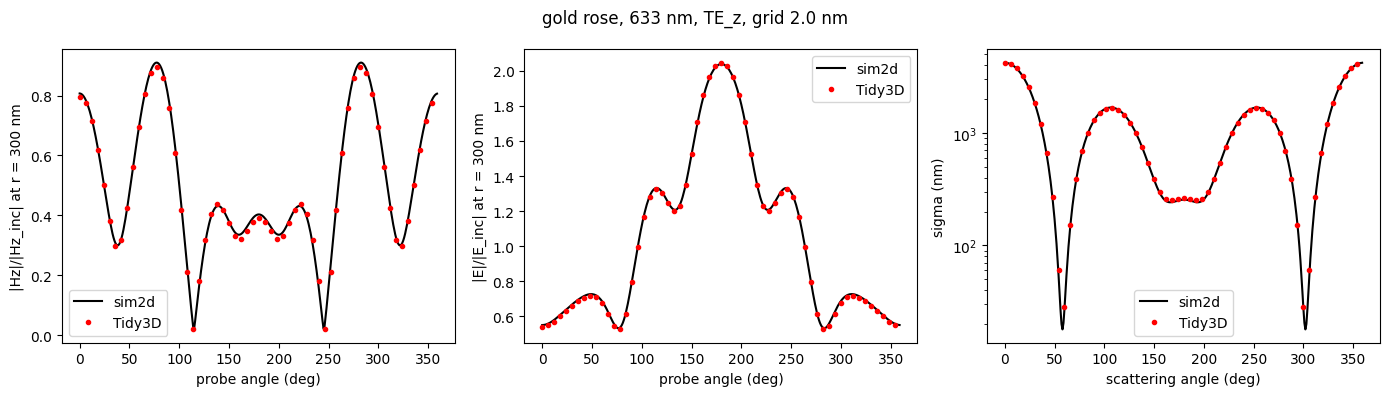

In [ ]:
deg = np.rad2deg(phis)
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(deg, R['probe_absHz'], 'k-', label='sim2d'); axs[0].plot(deg[::6], absHz[::6], 'ro', ms=3, label='Tidy3D')
axs[0].set(xlabel='probe angle (deg)', ylabel='|Hz|/|Hz_inc| at r = 300 nm'); axs[0].legend()
axs[1].plot(deg, R['probe_absE'], 'k-', label='sim2d'); axs[1].plot(deg[::6], absE[::6], 'ro', ms=3, label='Tidy3D')
axs[1].set(xlabel='probe angle (deg)', ylabel='|E|/|E_inc| at r = 300 nm'); axs[1].legend()
axs[2].semilogy(deg, R['sigma'], 'k-', label='sim2d'); axs[2].semilogy(deg[::6], sigma[::6], 'ro', ms=3, label='Tidy3D')
axs[2].set(xlabel='scattering angle (deg)', ylabel='sigma (nm)'); axs[2].legend()
fig.suptitle(f'{MATERIAL} rose, 633 nm, TE_z, grid {DL_NM} nm'); fig.tight_layout(); plt.show()

if MODE == 'broadband':
    fig, ax = plt.subplots(figsize=(6, 4))
    lr = np.array(R['spec_lam'])
    for q, col in (('Cext', 'k'), ('Csca', 'b'), ('Cabs', 'r')):
        ax.plot(lr, R['spec_' + q], col + '-', label=q + ' sim2d')
    ax.plot(lams/NM, Cext, 'ko', ms=4, label='Cext Tidy3D'); ax.plot(lams/NM, Csca, 'bs', ms=4, label='Csca Tidy3D')
    ax.plot(lams/NM, Cabs, 'r^', ms=4, label='Cabs Tidy3D')
    ax.set(xlabel='wavelength (nm)', ylabel='cross section per unit length (nm)', title=f'{MATERIAL} rose, TE_z')
    ax.legend(fontsize=8); fig.tight_layout(); plt.show()

In [ ]:
# save results (Files panel on the left, or download)
np.savetxt(f'tidy3d_{tag}_cross_sections.csv', np.column_stack([lams/NM, Cext, Csca, Cabs]), delimiter=',',
           header='lambda_nm,Cext_nm,Csca_nm,Cabs_nm', comments='')
np.savetxt(f'tidy3d_{tag}_633nm_probe_r300.csv', np.column_stack([deg, absHz, absE]), delimiter=',',
           header='phi_deg,absHz_over_absHzinc,absE_over_absEinc', comments='')
np.savetxt(f'tidy3d_{tag}_633nm_sigma.csv', np.column_stack([deg, sigma]), delimiter=',',
           header='phi_deg,sigma_nm', comments='')
try:
    from google.colab import files
    for f in (f'tidy3d_{tag}_cross_sections.csv', f'tidy3d_{tag}_633nm_probe_r300.csv', f'tidy3d_{tag}_633nm_sigma.csv'):
        files.download(f)
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>